# Section 10. Disclosed Fair Value, Issue Margin, and Hedge Allocation

이 노트북은 미래에셋증권이 투자설명서에 제시한 **공시 공정가액**을 외생적인 ELS fair value로 사용한다.

따라서 여기서는 실제 발행사의 pricing engine을 복제하지 않는다. 대신 다음 질문에 집중한다.

1. 공시 공정가액과 발행금액 100억원의 차이로 계산한 발행마진은 얼마인가?
2. 판매수수료 0.5%를 차감하면 net issue margin은 얼마인가?
3. net issue margin을 반영하고 동적헤지 거래비용 30bp를 고정하면 어떤 hedge allocation이 발행사 terminal balance와 tail risk를 가장 잘 균형시키는가?

이 노트북은 결과를 파일로 저장하지 않고, 모든 표와 그래프를 노트북 내부 출력으로만 확인한다.

## 10-0. 분석 논리

이전 Section 10의 Black-Scholes fair value는 단순 benchmark로만 남긴다.  
본 섹션의 핵심 논리는 다음과 같다.

```text
공시 공정가액 비율 = 1증권당 공정가액 / 1증권당 발행가액
총 공정가액 = 총 발행금액 × 공시 공정가액 비율
gross issue margin = 총 발행금액 - 총 공정가액
sales fee = 총 발행금액 × 0.5%
net issue margin = gross issue margin - sales fee
```

이후 운용 시뮬레이션에서는 기존 프로젝트의 상수변동성 path, FDM delta, static hedge, dynamic hedge 로직을 사용한다.

공시 fair value는 **발행 시점의 pricing input**이고, terminal balance는 **path가 지나간 뒤 payoff와 hedge 손익까지 반영한 실현 잔고**다.

In [1]:
# ============================================================
# 10-1. Import and Notebook Display Setting
# ============================================================

# 수치 계산, 표 정리, 그래프 작성을 위한 기본 패키지다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 프로젝트 경로 탐색과 노트북 출력 표시를 위한 도구다.
from pathlib import Path
from IPython.display import display, Markdown

# 노트북 실행 중 불필요한 경고를 숨겨 결과 표와 그래프를 읽기 쉽게 둔다.
import warnings
warnings.filterwarnings("ignore")

# 금액은 억원 단위 컬럼으로 많이 볼 예정이므로 소수점 네 자리까지 표시한다.
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
# ============================================================
# 10-2. Project Path and Existing Result Loading
# ============================================================

# 이 노트북은 ELS hege 5.19 폴더 안에서 실행하는 것을 기준으로 한다.
# 다른 위치에서 실행해도 상위 폴더를 탐색해 프로젝트 폴더를 찾는다.
PROJECT_NAME = "ELS hege 5.19"
current = Path.cwd().resolve()

if current.name == PROJECT_NAME:
    PROJECT_DIR = current
else:
    PROJECT_DIR = None
    for parent in [current, *current.parents]:
        candidate = parent / PROJECT_NAME
        if candidate.exists():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is None:
        raise FileNotFoundError(f"Cannot find project folder: {PROJECT_NAME}")

OUTPUT_DIR = PROJECT_DIR / "output"

# 기존 섹션들이 만든 결과는 읽기만 한다.
market_params = pd.read_csv(OUTPUT_DIR / "market_params.csv").iloc[0].to_dict()
payoff_df = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv").reset_index()
experiment_grid = experiment_grid.rename(columns={"index": "experiment_id"})
static_metadata = pd.read_csv(OUTPUT_DIR / "static_hedge_metadata.csv")

sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

paths = np.load(OUTPUT_DIR / "mc_paths.npy")
static_pnl_terminal_matrix = np.load(OUTPUT_DIR / "static_pnl_terminal_matrix.npy")

# 동적헤지 30bp 비용을 pathwise로 다시 계산하기 위해 FDM delta grid를 읽는다.
S_GRID = np.load(OUTPUT_DIR / "fdm_S_GRID.npy")
delta_ki_grid = np.load(OUTPUT_DIR / "fdm_delta_ki_grid.npy")
delta_noki_grid = np.load(OUTPUT_DIR / "fdm_delta_noki_grid.npy")

load_check = pd.DataFrame({
    "item": [
        "market_params", "payoff_df", "experiment_grid",
        "static_metadata", "sim_dates", "paths"
    ],
    "shape_or_length": [
        "1 row", payoff_df.shape, experiment_grid.shape,
        static_metadata.shape, len(sim_dates), paths.shape
    ],
})

display(load_check)

,item,shape_or_length
0,market_params,1 row
1,payoff_df,"(10000, 12)"
2,experiment_grid,"(33, 9)"
3,static_metadata,"(33, 17)"
4,sim_dates,780
5,paths,"(10000, 780)"


In [3]:
# ============================================================
# 10-3. Disclosed Fair Value and Fee Assumptions
# ============================================================

# 총 발행금액은 미래에셋 문서의 발행한도/모집총액 100억원을 전액 모집했다고 가정한 값이다.
# 1증권당 발행가액과 공정가액은 같은 비율로 총액에 적용된다.
ISSUE_AMOUNT = 10_000_000_000
ISSUE_PRICE_PER_NOTE = 10_000.00

# 미래에셋 투자설명서에 기재된 1증권당 공정가액을 입력한다.
# 문서 값이 다르면 이 숫자 하나만 바꾸면 아래 표와 그래프가 모두 재계산된다.
DISCLOSED_FAIR_VALUE_PER_NOTE = 9_452.78

# 사용자 요청에 따라 판매수수료는 0.5%로 고정한다.
SALES_FEE_RATE = 0.005

# 사용자 요청에 따라 동적헤지 거래비용은 30bp로 고정한다.
DYNAMIC_TC_BPS = 30

# 기존 프로젝트와 같은 운용 가정이다.
S0 = float(market_params["S0"])
RISK_FREE_RATE = float(market_params["RISK_FREE_RATE"])
PRINCIPAL_DAILY_RATE = 0.03 / 365
KNOCK_IN_BARRIER = 0.35
NOTIONAL = ISSUE_AMOUNT

# 공시 공정가액 비율을 총 발행금액에 적용해 aggregate fair value를 만든다.
disclosed_fair_value_ratio = DISCLOSED_FAIR_VALUE_PER_NOTE / ISSUE_PRICE_PER_NOTE
aggregate_disclosed_fair_value = ISSUE_AMOUNT * disclosed_fair_value_ratio
gross_issue_margin = ISSUE_AMOUNT - aggregate_disclosed_fair_value
sales_fee = ISSUE_AMOUNT * SALES_FEE_RATE
net_issue_margin = gross_issue_margin - sales_fee

margin_input_table = pd.DataFrame([
    ["Issue amount", ISSUE_AMOUNT / 1e8, "억원", "전액 모집된 총 투자자 납입금"],
    ["Issue price per note", ISSUE_PRICE_PER_NOTE, "원", "1증권당 발행가액"],
    ["Disclosed fair value per note", DISCLOSED_FAIR_VALUE_PER_NOTE, "원", "투자설명서 공시 공정가액"],
    ["Disclosed fair value ratio", disclosed_fair_value_ratio, "ratio", "공정가액 / 발행가액"],
    ["Aggregate disclosed fair value", aggregate_disclosed_fair_value / 1e8, "억원", "총 발행금액에 비율 적용"],
    ["Gross issue margin", gross_issue_margin / 1e8, "억원", "발행금액 - 공시 공정가액"],
    ["Sales fee", sales_fee / 1e8, "억원", "발행금액 × 0.5%"],
    ["Net issue margin", net_issue_margin / 1e8, "억원", "gross margin - sales fee"],
    ["Dynamic hedge transaction cost", DYNAMIC_TC_BPS, "bp", "운용 시뮬레이션에서 고정"],
], columns=["input", "value", "unit", "comment"])

display(margin_input_table)

,input,value,unit,comment
0,Issue amount,100.0000,억원,전액 모집된 총 투자자 납입금
1,Issue price per note,"10,000.0000",원,1증권당 발행가액
2,Disclosed fair value per note,"9,452.7800",원,투자설명서 공시 공정가액
3,Disclosed fair value ratio,0.9453,ratio,공정가액 / 발행가액
4,Aggregate disclosed fair value,94.5278,억원,총 발행금액에 비율 적용
5,Gross issue margin,5.4722,억원,발행금액 - 공시 공정가액
6,Sales fee,0.5000,억원,발행금액 × 0.5%
7,Net issue margin,4.9722,억원,gross margin - sales fee
8,Dynamic hedge transaction cost,30.0000,bp,운용 시뮬레이션에서 고정


,component,amount_100m
0,Disclosed fair value,94.5278
1,Sales fee,0.5000
2,Net issue margin,4.9722


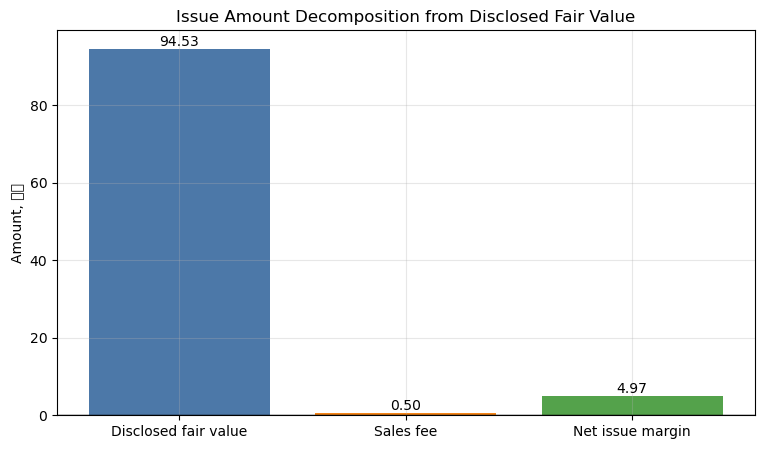

In [4]:
# ============================================================
# 10-4. Issue Margin Waterfall
# ============================================================

# 발행금액 100억원이 공시 공정가액, 판매수수료, net issue margin으로 어떻게 나뉘는지 시각화한다.
waterfall = pd.DataFrame({
    "component": ["Disclosed fair value", "Sales fee", "Net issue margin"],
    "amount_100m": [
        aggregate_disclosed_fair_value / 1e8,
        sales_fee / 1e8,
        net_issue_margin / 1e8,
    ],
})

display(waterfall)

plt.figure(figsize=(9, 5))
colors = ["#4C78A8", "#F58518", "#54A24B"]
plt.bar(waterfall["component"], waterfall["amount_100m"], color=colors)
plt.axhline(0, color="black", linewidth=1)
plt.title("Issue Amount Decomposition from Disclosed Fair Value")
plt.ylabel("Amount, 억원")
for idx, row in waterfall.iterrows():
    plt.text(idx, row["amount_100m"], f"{row['amount_100m']:.2f}", ha="center", va="bottom")
plt.show()

In [5]:
# ============================================================
# 10-5. Growth Factors and Existing Account Components
# ============================================================

# terminal balance를 비교하기 위해 모든 현금흐름을 프로젝트의 최종 만기일 가치로 환산한다.
def cash_growth_factor_by_calendar_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    '''캘린더 일수 기준 현금성 계좌 성장계수.'''
    return (1 + daily_rate) ** n_days

n_paths = len(payoff_df)
n_experiments = len(experiment_grid)

settlement_index = payoff_df["settlement_index"].astype(int).values
issuer_cash_outflow = payoff_df["issuer_cash_outflow"].astype(float).values

issue_date = sim_dates[0]
final_date = sim_dates[-1]
settlement_dates = sim_dates[settlement_index]

days_settlement_to_maturity = np.array([(final_date - d).days for d in settlement_dates])
total_days_to_maturity = (final_date - issue_date).days

growth_settlement_to_maturity = cash_growth_factor_by_calendar_days(days_settlement_to_maturity)
growth_full_maturity = cash_growth_factor_by_calendar_days(total_days_to_maturity)

# net issue margin은 발행 시점에 확보한 현금 buffer로 보고 만기까지 현금성 계좌로 운용한다.
net_issue_margin_terminal = net_issue_margin * growth_full_maturity

# 원금북, 정적헤지 계좌, payoff 차감액을 명확하게 분리한다.
principal_account_terminal_matrix = np.zeros((n_experiments, n_paths))
static_hedge_account_terminal_matrix = np.zeros((n_experiments, n_paths))
payoff_terminal_equivalent_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    principal_amount = float(row["principal_book_amount"])
    static_budget = float(row["static_budget"])

    # 원금북은 채권/현금성 계좌처럼 만기까지 운용된다고 본다.
    principal_account_terminal_matrix[i, :] = principal_amount * growth_full_maturity

    # 정적헤지 계좌는 static budget의 현금 담보 성장분과 short put 손익을 더한다.
    static_cash_collateral_terminal = static_budget * growth_full_maturity
    static_hedge_account_terminal_matrix[i, :] = (
        static_cash_collateral_terminal + static_pnl_terminal_matrix[i, :]
    )

    # payoff는 settlement 시점 지급액을 만기시점 가치로 환산하여 차감한다.
    payoff_terminal_equivalent_matrix[i, :] = issuer_cash_outflow * growth_settlement_to_maturity

growth_table = pd.DataFrame([
    ["Issue date", str(issue_date.date())],
    ["Final date", str(final_date.date())],
    ["Total calendar days", total_days_to_maturity],
    ["Growth full maturity", growth_full_maturity],
    ["Net issue margin terminal value, 억원", net_issue_margin_terminal / 1e8],
], columns=["metric", "value"])

display(growth_table)

,metric,value
0,Issue date,2026-05-14
1,Final date,2029-05-09
2,Total calendar days,1091
3,Growth full maturity,1.0938
4,"Net issue margin terminal value, 억원",5.4386


In [6]:
# ============================================================
# 10-6. Dynamic Hedge Account with Fixed 30bp Transaction Cost
# ============================================================

# FDM delta grid에서 현재 가격과 KI 상태에 맞는 delta를 보간한다.
def lookup_delta_vectorized(S_values, time_index, ki_states):
    '''FDM delta grid lookup with linear interpolation.'''
    time_index = int(np.clip(time_index, 0, delta_ki_grid.shape[0] - 1))
    S_clipped = np.clip(S_values, S_GRID[0], S_GRID[-1])
    delta_noki = np.interp(S_clipped, S_GRID, delta_noki_grid[time_index, :])
    delta_ki = np.interp(S_clipped, S_GRID, delta_ki_grid[time_index, :])
    return np.where(ki_states, delta_ki, delta_noki)

# 각 path가 특정 시점까지 knock-in 상태에 들어갔는지 표시한다.
ki_state_matrix = np.minimum.accumulate(paths, axis=1) <= (KNOCK_IN_BARRIER * S0)

# weekly rebalancing과 settlement 시점을 모두 거래 가능 시점으로 둔다.
n_time = paths.shape[1]
n_steps = n_time - 1
weekly_rebal_indices = np.arange(0, n_steps + 1, 5)
settlement_indices = payoff_df["settlement_index"].astype(int).unique()
trading_indices = np.unique(np.concatenate([weekly_rebal_indices, settlement_indices, np.array([n_steps])]))
trading_indices = np.sort(trading_indices)


def run_dynamic_hedge_with_tc(row, transaction_cost_bps=DYNAMIC_TC_BPS):
    '''
    한 전략(row)에 대해 30bp 거래비용을 반영한 동적헤지 현금계좌를 pathwise 계산한다.

    거래비용은 매 리밸런싱의 절대 거래금액 × 30bp로 현금계좌에서 직접 차감한다.
    '''
    dynamic_ratio = float(row["dynamic_ratio"])
    dynamic_budget = float(row["dynamic_budget"])
    tc_rate = transaction_cost_bps * 1e-4

    cash = np.full(n_paths, dynamic_budget, dtype=float)
    units = np.zeros(n_paths, dtype=float)
    active = np.ones(n_paths, dtype=bool)

    transaction_cost_paid = np.zeros(n_paths)
    turnover = np.zeros(n_paths)
    last_idx = 0

    for idx in trading_indices:
        idx = int(idx)

        # 리밸런싱 사이의 기간 동안 현금계좌는 일복리로 성장한다.
        n_days = idx - last_idx
        if n_days > 0:
            cash *= cash_growth_factor_by_calendar_days(n_days)

        S_t = paths[:, idx]

        # 조기상환 또는 만기 도달 path는 기존 포지션을 청산하고 더 이상 리밸런싱하지 않는다.
        settle_now = active & (settlement_index == idx)
        if np.any(settle_now):
            close_notional = np.abs(units[settle_now] * S_t[settle_now])
            close_cost = tc_rate * close_notional
            cash[settle_now] += units[settle_now] * S_t[settle_now]
            cash[settle_now] -= close_cost
            transaction_cost_paid[settle_now] += close_cost
            turnover[settle_now] += close_notional
            units[settle_now] = 0.0
            active[settle_now] = False

        # 아직 살아있는 path는 FDM delta에 맞춰 hedge position을 조정한다.
        rebalance_now = active
        if np.any(rebalance_now):
            S_active = S_t[rebalance_now]
            ki_active = ki_state_matrix[rebalance_now, idx]
            liability_delta = lookup_delta_vectorized(S_active, idx, ki_active)

            target_units_uncapped = liability_delta * dynamic_ratio
            position_value_uncapped = target_units_uncapped * S_active
            abs_position_value = np.abs(position_value_uncapped)

            # hedge budget을 넘는 포지션은 예산 한도 안으로 축소한다.
            cap_factor = np.ones_like(target_units_uncapped)
            binding = abs_position_value > dynamic_budget
            cap_factor[binding] = dynamic_budget / (abs_position_value[binding] + 1e-12)
            target_units = target_units_uncapped * cap_factor

            old_units = units[rebalance_now]
            trade_units = target_units - old_units
            trade_notional = np.abs(trade_units * S_active)
            transaction_cost = tc_rate * trade_notional

            cash[rebalance_now] -= trade_units * S_active
            cash[rebalance_now] -= transaction_cost
            units[rebalance_now] = target_units

            transaction_cost_paid[rebalance_now] += transaction_cost
            turnover[rebalance_now] += trade_notional

        last_idx = idx

    # 만기까지 살아있는 path는 마지막 시점에 남은 포지션을 청산한다.
    final_S = paths[:, -1]
    still_active = active
    if np.any(still_active):
        close_notional = np.abs(units[still_active] * final_S[still_active])
        close_cost = tc_rate * close_notional
        cash[still_active] += units[still_active] * final_S[still_active]
        cash[still_active] -= close_cost
        transaction_cost_paid[still_active] += close_cost
        turnover[still_active] += close_notional

    return cash, transaction_cost_paid, turnover


# 모든 전략에 대해 30bp 동적헤지 계좌와 거래비용을 계산한다.
dynamic_account_30bp_matrix = np.zeros((n_experiments, n_paths))
dynamic_tc_30bp_matrix = np.zeros((n_experiments, n_paths))
dynamic_turnover_matrix = np.zeros((n_experiments, n_paths))

for i, row in experiment_grid.iterrows():
    cash, tc_paid, turnover = run_dynamic_hedge_with_tc(row, transaction_cost_bps=DYNAMIC_TC_BPS)
    dynamic_account_30bp_matrix[i, :] = cash
    dynamic_tc_30bp_matrix[i, :] = tc_paid
    dynamic_turnover_matrix[i, :] = turnover

tc_check = pd.DataFrame([
    ["Dynamic transaction cost", DYNAMIC_TC_BPS, "bp"],
    ["Mean transaction cost paid", dynamic_tc_30bp_matrix.mean() / 1e8, "억원"],
    ["95% transaction cost paid", np.percentile(dynamic_tc_30bp_matrix, 95) / 1e8, "억원"],
    ["Mean turnover", dynamic_turnover_matrix.mean() / 1e8, "억원"],
], columns=["metric", "value", "unit"])

display(tc_check)

,metric,value,unit
0,Dynamic transaction cost,30.0000,bp
1,Mean transaction cost paid,0.1684,억원
2,95% transaction cost paid,0.9273,억원
3,Mean turnover,56.1177,억원


In [7]:
# ============================================================
# 10-7. Strategy Summary with Disclosed Fair Value Margin
# ============================================================

# 발행사 terminal balance는 원금북 + 정적헤지 + 동적헤지 + net issue margin - 투자자 payoff로 계산한다.
terminal_balance_matrix = (
    principal_account_terminal_matrix
    + static_hedge_account_terminal_matrix
    + dynamic_account_30bp_matrix
    + net_issue_margin_terminal
    - payoff_terminal_equivalent_matrix
)

summary_rows = []

for i, row in experiment_grid.iterrows():
    tb = terminal_balance_matrix[i, :]
    p05 = np.percentile(tb, 5)
    cvar05 = tb[tb <= p05].mean()

    # static short put의 used margin은 비용이라기보다 헤지 자본 사용량이다.
    # 명시적 비용은 동적헤지 거래비용으로 보고, static margin은 resource usage로 따로 보여준다.
    used_static_margin = float(static_metadata.loc[i, "used_static_margin"])

    summary_rows.append({
        "experiment_id": int(row["experiment_id"]),
        "principal_book_ratio": float(row["principal_book_ratio"]),
        "hedge_book_ratio": float(row["hedge_book_ratio"]),
        "static_ratio": float(row["static_ratio"]),
        "dynamic_ratio": float(row["dynamic_ratio"]),
        "used_static_margin_100m": used_static_margin / 1e8,
        "dynamic_budget_100m": float(row["dynamic_budget"]) / 1e8,
        "net_issue_margin_terminal_100m": net_issue_margin_terminal / 1e8,
        "mean_dynamic_tc_paid_100m": dynamic_tc_30bp_matrix[i, :].mean() / 1e8,
        "p95_dynamic_tc_paid_100m": np.percentile(dynamic_tc_30bp_matrix[i, :], 95) / 1e8,
        "mean_turnover_100m": dynamic_turnover_matrix[i, :].mean() / 1e8,
        "mean_terminal_balance_100m": tb.mean() / 1e8,
        "p05_terminal_balance_100m": p05 / 1e8,
        "cvar05_terminal_balance_100m": cvar05 / 1e8,
        "issuer_no_shortfall_probability": np.mean(tb >= 0),
        "capital_required_95_100m": max(-p05, 0) / 1e8,
    })

strategy_summary = pd.DataFrame(summary_rows)

# 여러 지표를 동시에 보기 위한 단순 표준화 점수다.
# 점수는 결론을 강제하는 값이 아니라, 평균수익/꼬리위험/비용을 한 번에 정렬하기 위한 보조 지표다.
score_df = strategy_summary.copy()

def zscore(series):
    std = series.std(ddof=0)
    if std == 0:
        return series * 0
    return (series - series.mean()) / std

strategy_summary["balanced_score"] = (
    zscore(score_df["mean_terminal_balance_100m"])
    + zscore(score_df["cvar05_terminal_balance_100m"])
    + zscore(score_df["issuer_no_shortfall_probability"])
    - zscore(score_df["mean_dynamic_tc_paid_100m"])
    - zscore(score_df["capital_required_95_100m"])
)

display(strategy_summary.head(34))

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,used_static_margin_100m,dynamic_budget_100m,net_issue_margin_terminal_100m,mean_dynamic_tc_paid_100m,p95_dynamic_tc_paid_100m,mean_turnover_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m,balanced_score
0,0,0.3000,0.7000,0.0000,1.0000,0.0000,70.0000,5.4386,0.3903,2.1904,130.1053,-1.2175,-6.3778,-16.3403,0.0613,6.3778,-4.1155
1,1,0.3000,0.7000,0.1000,0.9000,6.6596,63.0000,5.4386,0.3513,1.9713,117.0947,-0.9826,-7.0180,-17.0646,0.0679,7.0180,-4.0583
2,2,0.3000,0.7000,0.2000,0.8000,13.3191,56.0000,5.4386,0.3123,1.7523,104.0842,-0.7477,-7.7437,-17.9054,0.4788,7.7437,-2.1743
3,3,0.3000,0.7000,0.3000,0.7000,19.9787,49.0000,5.4386,0.2732,1.5333,91.0737,-0.5128,-8.3810,-18.8292,0.6729,8.3810,-1.3048
4,4,0.3000,0.7000,0.4000,0.6000,26.6383,42.0000,5.4386,0.2342,1.3142,78.0632,-0.2779,-8.8102,-19.7977,0.7453,8.8102,-0.9048
5,5,0.3000,0.7000,0.5000,0.5000,33.2979,35.0000,5.4386,0.1952,1.0952,65.0526,-0.0430,-9.2762,-20.7929,0.7815,9.2762,-0.7119
6,6,0.3000,0.7000,0.6000,0.4000,39.9574,28.0000,5.4386,0.1561,0.8761,52.0421,0.1919,-9.6693,-21.8113,0.7989,9.6693,-0.5730
7,7,0.3000,0.7000,0.7000,0.3000,46.6170,21.0000,5.4386,0.1171,0.6571,39.0316,0.4268,-9.9795,-22.8485,0.8121,9.9795,-0.4100
8,8,0.3000,0.7000,0.8000,0.2000,53.2766,14.0000,5.4386,0.0781,0.4381,26.0211,0.6616,-10.1247,-23.8962,0.8220,10.1247,-0.1639
9,9,0.3000,0.7000,0.9000,0.1000,59.9362,7.0000,5.4386,0.0390,0.2190,13.0105,0.8965,-10.4084,-24.9562,0.8269,10.4084,-0.0337


In [8]:
# ============================================================
# 10-8. Investor Payoff Metrics
# ============================================================

# 투자자 payoff 자체는 상품 조건이 결정하므로 hedge allocation에 따라 달라지지 않는다.
# 따라서 발행사 terminal balance와 분리해서 별도 표로 확인한다.
investor_metrics = pd.DataFrame([{
    "principal_recovery_probability": np.mean(payoff_df["investor_payoff"] >= NOTIONAL),
    "loss_probability": np.mean(payoff_df["investor_payoff"] < NOTIONAL),
    "autocall_probability": np.mean(payoff_df["autocall_occurred"]),
    "knock_in_probability": np.mean(payoff_df["knock_in_occurred"]),
    "mean_investor_payoff_100m": payoff_df["investor_payoff"].mean() / 1e8,
    "p05_investor_payoff_100m": np.percentile(payoff_df["investor_payoff"], 5) / 1e8,
}])

display(investor_metrics)

,principal_recovery_probability,loss_probability,autocall_probability,knock_in_probability,mean_investor_payoff_100m,p05_investor_payoff_100m
0,0.9870,0.0130,0.9412,0.0264,106.5371,104.8500


In [9]:
# ============================================================
# 10-9. Strategy Ranking Tables
# ============================================================

show_cols = [
    "experiment_id",
    "principal_book_ratio",
    "hedge_book_ratio",
    "static_ratio",
    "dynamic_ratio",
    "net_issue_margin_terminal_100m",
    "used_static_margin_100m",
    "mean_dynamic_tc_paid_100m",
    "mean_terminal_balance_100m",
    "p05_terminal_balance_100m",
    "cvar05_terminal_balance_100m",
    "issuer_no_shortfall_probability",
    "capital_required_95_100m",
    "balanced_score",
]

rank_by_mean = strategy_summary.sort_values("mean_terminal_balance_100m", ascending=False).head(10)
rank_by_cvar = strategy_summary.sort_values("cvar05_terminal_balance_100m", ascending=False).head(10)
rank_by_cost = strategy_summary.sort_values("mean_dynamic_tc_paid_100m", ascending=True).head(10)
rank_by_score = strategy_summary.sort_values("balanced_score", ascending=False).head(10)

display(Markdown("### Top 10 by mean terminal balance"))
display(rank_by_mean[show_cols])

display(Markdown("### Top 10 by CVaR 5%, less negative is better"))
display(rank_by_cvar[show_cols])

display(Markdown("### Top 10 by lower dynamic hedge transaction cost"))
display(rank_by_cost[show_cols])

display(Markdown("### Top 10 by balanced score"))
display(rank_by_score[show_cols])

### Top 10 by mean terminal balance

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,used_static_margin_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m,balanced_score
10,10,0.3000,0.7000,1.0000,0.0000,5.4386,66.5957,0.0000,1.1314,-10.5554,-23.7298,0.8305,10.5554,1.1446
21,21,0.5000,0.5000,1.0000,0.0000,5.4386,50.0000,0.0000,1.1164,-11.4837,-21.3750,0.8231,11.4837,1.5010
32,32,0.7000,0.3000,1.0000,0.0000,5.4386,30.0000,0.0000,1.0983,-12.6023,-18.5371,0.8168,12.6023,1.9431
31,31,0.7000,0.3000,0.9000,0.1000,5.4386,27.0000,0.0276,0.9849,-12.4401,-19.1673,0.8168,12.4401,1.3436
20,20,0.5000,0.5000,0.9000,0.1000,5.4386,45.0000,0.0343,0.9409,-11.3155,-22.3656,0.8210,11.3155,0.5816
9,9,0.3000,0.7000,0.9000,0.1000,5.4386,59.9362,0.0390,0.8965,-10.4084,-24.9562,0.8269,10.4084,-0.0337
30,30,0.7000,0.3000,0.8000,0.2000,5.4386,24.0000,0.0553,0.8715,-12.0778,-18.7757,0.8168,12.0778,1.3024
19,19,0.5000,0.5000,0.8000,0.2000,5.4386,40.0000,0.0687,0.7655,-11.0553,-21.6451,0.8201,11.0553,0.4504
29,29,0.7000,0.3000,0.7000,0.3000,5.4386,21.0000,0.0829,0.7582,-11.8034,-18.3921,0.8169,11.8034,1.2032
8,8,0.3000,0.7000,0.8000,0.2000,5.4386,53.2766,0.0781,0.6616,-10.1247,-23.8962,0.8220,10.1247,-0.1639


### Top 10 by CVaR 5%, less negative is better

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,used_static_margin_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m,balanced_score
0,0,0.3000,0.7000,0.0000,1.0000,5.4386,0.0000,0.3903,-1.2175,-6.3778,-16.3403,0.0613,6.3778,-4.1155
22,22,0.7000,0.3000,0.0000,1.0000,5.4386,0.0000,0.2764,-0.0354,-8.6035,-16.3657,0.7752,8.6035,0.8286
23,23,0.7000,0.3000,0.1000,0.9000,5.4386,3.0000,0.2488,0.0780,-9.0261,-16.5779,0.8025,9.0261,1.0384
11,11,0.5000,0.5000,0.0000,1.0000,5.4386,0.0000,0.3434,-0.6382,-6.8044,-16.7615,0.1692,6.8044,-2.6851
24,24,0.7000,0.3000,0.2000,0.8000,5.4386,6.0000,0.2211,0.1914,-9.6299,-16.8181,0.8137,9.6299,1.0459
1,1,0.3000,0.7000,0.1000,0.9000,5.4386,6.6596,0.3513,-0.9826,-7.0180,-17.0646,0.0679,7.0180,-4.0583
25,25,0.7000,0.3000,0.3000,0.7000,5.4386,9.0000,0.1935,0.3047,-10.0658,-17.0781,0.8193,10.0658,1.1235
12,12,0.5000,0.5000,0.1000,0.9000,5.4386,5.0000,0.3090,-0.4628,-7.5126,-17.2304,0.6344,7.5126,-0.5119
26,26,0.7000,0.3000,0.4000,0.6000,5.4386,12.0000,0.1659,0.4181,-10.5758,-17.3674,0.8209,10.5758,1.1232
27,27,0.7000,0.3000,0.5000,0.5000,5.4386,15.0000,0.1382,0.5315,-11.0302,-17.6853,0.8193,11.0302,1.1302


### Top 10 by lower dynamic hedge transaction cost

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,used_static_margin_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m,balanced_score
32,32,0.7000,0.3000,1.0000,0.0000,5.4386,30.0000,0.0000,1.0983,-12.6023,-18.5371,0.8168,12.6023,1.9431
21,21,0.5000,0.5000,1.0000,0.0000,5.4386,50.0000,0.0000,1.1164,-11.4837,-21.3750,0.8231,11.4837,1.5010
10,10,0.3000,0.7000,1.0000,0.0000,5.4386,66.5957,0.0000,1.1314,-10.5554,-23.7298,0.8305,10.5554,1.1446
31,31,0.7000,0.3000,0.9000,0.1000,5.4386,27.0000,0.0276,0.9849,-12.4401,-19.1673,0.8168,12.4401,1.3436
20,20,0.5000,0.5000,0.9000,0.1000,5.4386,45.0000,0.0343,0.9409,-11.3155,-22.3656,0.8210,11.3155,0.5816
9,9,0.3000,0.7000,0.9000,0.1000,5.4386,59.9362,0.0390,0.8965,-10.4084,-24.9562,0.8269,10.4084,-0.0337
30,30,0.7000,0.3000,0.8000,0.2000,5.4386,24.0000,0.0553,0.8715,-12.0778,-18.7757,0.8168,12.0778,1.3024
19,19,0.5000,0.5000,0.8000,0.2000,5.4386,40.0000,0.0687,0.7655,-11.0553,-21.6451,0.8201,11.0553,0.4504
8,8,0.3000,0.7000,0.8000,0.2000,5.4386,53.2766,0.0781,0.6616,-10.1247,-23.8962,0.8220,10.1247,-0.1639
29,29,0.7000,0.3000,0.7000,0.3000,5.4386,21.0000,0.0829,0.7582,-11.8034,-18.3921,0.8169,11.8034,1.2032


### Top 10 by balanced score

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,net_issue_margin_terminal_100m,used_static_margin_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m,p05_terminal_balance_100m,cvar05_terminal_balance_100m,issuer_no_shortfall_probability,capital_required_95_100m,balanced_score
32,32,0.7000,0.3000,1.0000,0.0000,5.4386,30.0000,0.0000,1.0983,-12.6023,-18.5371,0.8168,12.6023,1.9431
21,21,0.5000,0.5000,1.0000,0.0000,5.4386,50.0000,0.0000,1.1164,-11.4837,-21.3750,0.8231,11.4837,1.5010
31,31,0.7000,0.3000,0.9000,0.1000,5.4386,27.0000,0.0276,0.9849,-12.4401,-19.1673,0.8168,12.4401,1.3436
30,30,0.7000,0.3000,0.8000,0.2000,5.4386,24.0000,0.0553,0.8715,-12.0778,-18.7757,0.8168,12.0778,1.3024
28,28,0.7000,0.3000,0.6000,0.4000,5.4386,18.0000,0.1106,0.6448,-11.3446,-18.0258,0.8174,11.3446,1.2140
29,29,0.7000,0.3000,0.7000,0.3000,5.4386,21.0000,0.0829,0.7582,-11.8034,-18.3921,0.8169,11.8034,1.2032
10,10,0.3000,0.7000,1.0000,0.0000,5.4386,66.5957,0.0000,1.1314,-10.5554,-23.7298,0.8305,10.5554,1.1446
27,27,0.7000,0.3000,0.5000,0.5000,5.4386,15.0000,0.1382,0.5315,-11.0302,-17.6853,0.8193,11.0302,1.1302
25,25,0.7000,0.3000,0.3000,0.7000,5.4386,9.0000,0.1935,0.3047,-10.0658,-17.0781,0.8193,10.0658,1.1235
26,26,0.7000,0.3000,0.4000,0.6000,5.4386,12.0000,0.1659,0.4181,-10.5758,-17.3674,0.8209,10.5758,1.1232


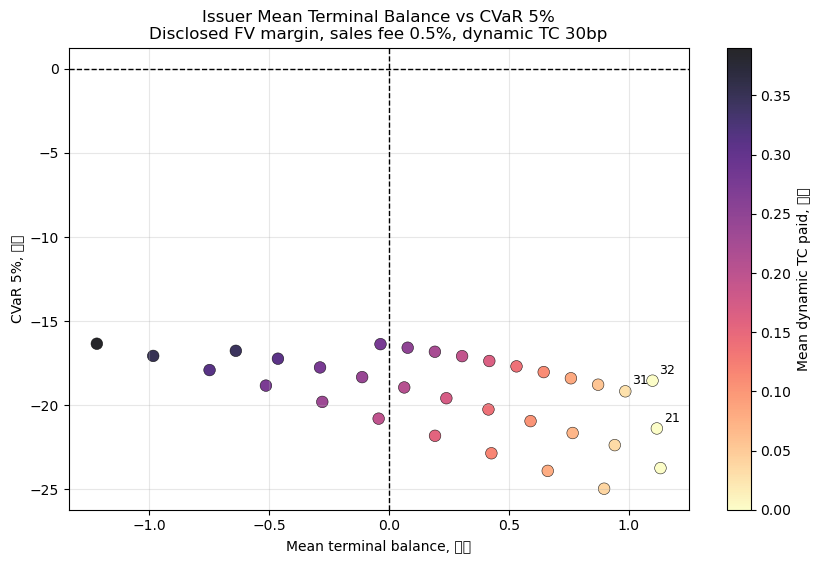

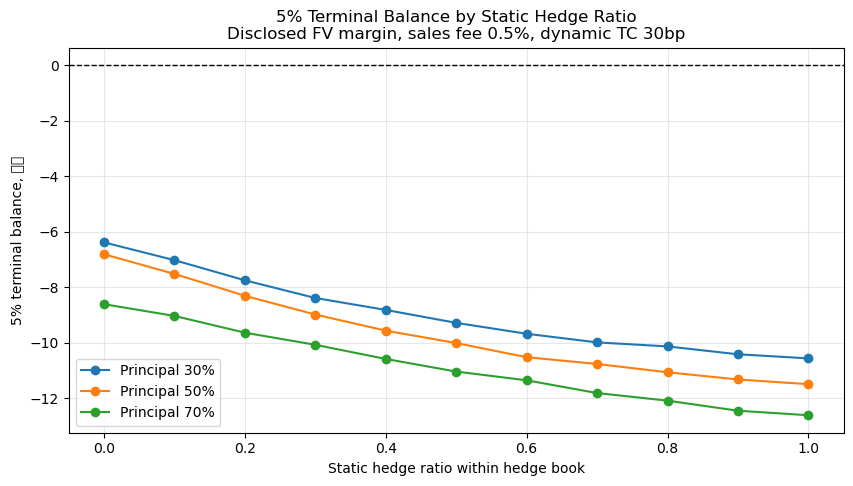

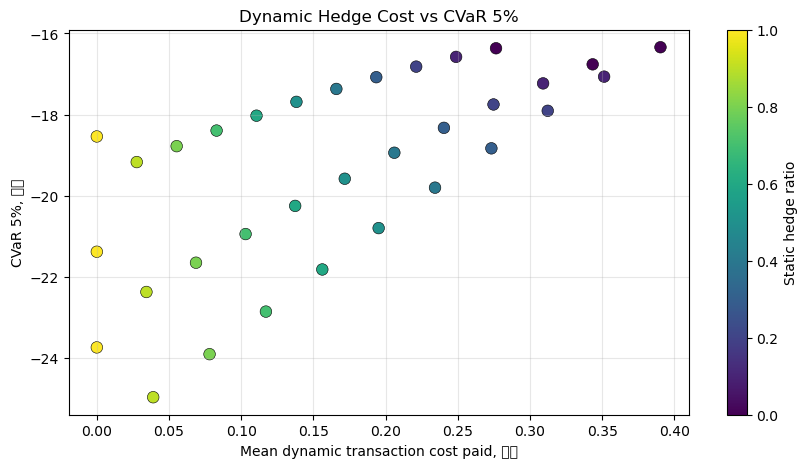

In [10]:
# ============================================================
# 10-10. Trade-off Graphs
# ============================================================

# 평균 terminal balance와 CVaR 5%의 trade-off를 본다.
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    strategy_summary["mean_terminal_balance_100m"],
    strategy_summary["cvar05_terminal_balance_100m"],
    c=strategy_summary["mean_dynamic_tc_paid_100m"],
    s=70,
    cmap="magma_r",
    edgecolor="black",
    linewidth=0.4,
    alpha=0.85,
)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Issuer Mean Terminal Balance vs CVaR 5%\nDisclosed FV margin, sales fee 0.5%, dynamic TC 30bp")
plt.xlabel("Mean terminal balance, 억원")
plt.ylabel("CVaR 5%, 억원")
cbar = plt.colorbar(scatter)
cbar.set_label("Mean dynamic TC paid, 억원")

for _, row in rank_by_score.head(3).iterrows():
    plt.annotate(
        int(row["experiment_id"]),
        (row["mean_terminal_balance_100m"], row["cvar05_terminal_balance_100m"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=9,
    )

plt.show()

# static/dynamic 배분이 5% terminal balance를 어떻게 바꾸는지 본다.
plt.figure(figsize=(10, 5))
for principal_ratio, temp in strategy_summary.groupby("principal_book_ratio"):
    temp = temp.sort_values("static_ratio")
    plt.plot(
        temp["static_ratio"],
        temp["p05_terminal_balance_100m"],
        marker="o",
        label=f"Principal {principal_ratio:.0%}",
    )
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("5% Terminal Balance by Static Hedge Ratio\nDisclosed FV margin, sales fee 0.5%, dynamic TC 30bp")
plt.xlabel("Static hedge ratio within hedge book")
plt.ylabel("5% terminal balance, 억원")
plt.legend()
plt.show()

# 비용과 tail risk의 관계를 본다.
plt.figure(figsize=(10, 5))
plt.scatter(
    strategy_summary["mean_dynamic_tc_paid_100m"],
    strategy_summary["cvar05_terminal_balance_100m"],
    c=strategy_summary["static_ratio"],
    cmap="viridis",
    s=70,
    edgecolor="black",
    linewidth=0.4,
)
plt.title("Dynamic Hedge Cost vs CVaR 5%")
plt.xlabel("Mean dynamic transaction cost paid, 억원")
plt.ylabel("CVaR 5%, 억원")
cbar = plt.colorbar()
cbar.set_label("Static hedge ratio")
plt.show()

Recommended balanced strategy: experiment 32, principal 70%, static 100%, dynamic 0%


,payoff_type,count,mean_min_price,mean_final_price,mean_investor_payoff_100m,mean_dynamic_tc_paid_100m,mean_terminal_balance_100m
0,autocall_6,129,52.3005,80.3523,129.1000,0.0000,-12.6023
1,maturity_no_knock_in,458,44.8121,53.1150,129.1000,0.0000,-20.2087


,path_id,payoff_type,autocall_no,knock_in_occurred,min_price,final_price,investor_payoff_100m,payoff_terminal_equivalent_100m,dynamic_tc_paid_100m,terminal_balance_100m,is_bottom_5pct
45,45,maturity_no_knock_in,0,False,39.0174,47.9958,129.1000,129.1000,0.0000,-22.5147,True
71,71,maturity_no_knock_in,0,False,55.9646,60.3852,129.1000,129.1000,0.0000,-16.9336,True
128,128,maturity_no_knock_in,0,False,53.4510,67.7207,129.1000,129.1000,0.0000,-13.6291,True
147,147,maturity_no_knock_in,0,False,35.4528,57.2939,129.1000,129.1000,0.0000,-18.3262,True
156,156,maturity_no_knock_in,0,False,49.9534,53.3120,129.1000,129.1000,0.0000,-20.1199,True
170,170,maturity_no_knock_in,0,False,45.5696,68.7058,129.1000,129.1000,0.0000,-13.1853,True
183,183,autocall_6,6,False,49.6530,74.5034,129.1000,129.1000,0.0000,-12.6023,True
207,207,maturity_no_knock_in,0,False,36.7829,45.8514,129.1000,129.1000,0.0000,-23.4808,True
211,211,maturity_no_knock_in,0,False,46.1687,47.5173,129.1000,129.1000,0.0000,-22.7303,True
217,217,autocall_6,6,False,45.1294,76.8554,129.1000,129.1000,0.0000,-12.6023,True


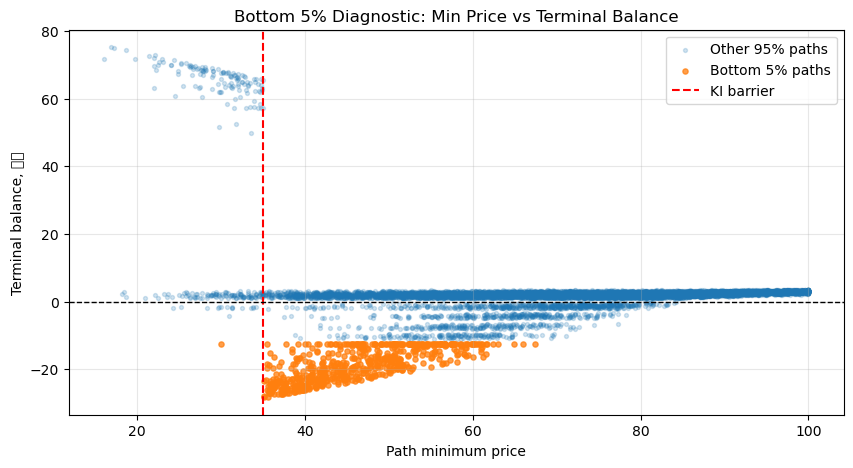

In [11]:
# ============================================================
# 10-11. Bottom 5% Path Diagnostics for Balanced Strategy
# ============================================================

# balanced score가 가장 높은 전략을 대표 전략으로 보고 하위 5% path를 분석한다.
recommended = rank_by_score.iloc[0]
recommended_id = int(recommended["experiment_id"])
recommended_tb = terminal_balance_matrix[recommended_id, :]

bottom_threshold = np.percentile(recommended_tb, 5)
bottom_mask = recommended_tb <= bottom_threshold

bottom_path_df = pd.DataFrame({
    "path_id": payoff_df["path_id"],
    "payoff_type": payoff_df["payoff_type"],
    "autocall_no": payoff_df["autocall_no"],
    "knock_in_occurred": payoff_df["knock_in_occurred"],
    "min_price": payoff_df["min_price"],
    "final_price": payoff_df["final_price"],
    "investor_payoff_100m": payoff_df["investor_payoff"] / 1e8,
    "payoff_terminal_equivalent_100m": payoff_terminal_equivalent_matrix[recommended_id, :] / 1e8,
    "dynamic_tc_paid_100m": dynamic_tc_30bp_matrix[recommended_id, :] / 1e8,
    "terminal_balance_100m": recommended_tb / 1e8,
    "is_bottom_5pct": bottom_mask,
})

bottom_summary = (
    bottom_path_df[bottom_path_df["is_bottom_5pct"]]
    .groupby("payoff_type")
    .agg(
        count=("path_id", "count"),
        mean_min_price=("min_price", "mean"),
        mean_final_price=("final_price", "mean"),
        mean_investor_payoff_100m=("investor_payoff_100m", "mean"),
        mean_dynamic_tc_paid_100m=("dynamic_tc_paid_100m", "mean"),
        mean_terminal_balance_100m=("terminal_balance_100m", "mean"),
    )
    .reset_index()
)

strategy_description = (
    f"experiment {recommended_id}, "
    f"principal {recommended['principal_book_ratio']:.0%}, "
    f"static {recommended['static_ratio']:.0%}, "
    f"dynamic {recommended['dynamic_ratio']:.0%}"
)

print("Recommended balanced strategy:", strategy_description)
display(bottom_summary)
display(bottom_path_df[bottom_path_df["is_bottom_5pct"]].head(20))

plt.figure(figsize=(10, 5))
plt.scatter(
    bottom_path_df.loc[~bottom_mask, "min_price"],
    bottom_path_df.loc[~bottom_mask, "terminal_balance_100m"],
    s=8,
    alpha=0.2,
    label="Other 95% paths",
)
plt.scatter(
    bottom_path_df.loc[bottom_mask, "min_price"],
    bottom_path_df.loc[bottom_mask, "terminal_balance_100m"],
    s=14,
    alpha=0.75,
    label="Bottom 5% paths",
)
plt.axvline(S0 * KNOCK_IN_BARRIER, color="red", linestyle="--", label="KI barrier")
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Bottom 5% Diagnostic: Min Price vs Terminal Balance")
plt.xlabel("Path minimum price")
plt.ylabel("Terminal balance, 억원")
plt.legend()
plt.show()

In [12]:
# ============================================================
# 10-12. Compact Interpretation
# ============================================================

# 보고서에 바로 옮길 수 있는 짧은 해석 문장이다.
best_mean = rank_by_mean.iloc[0]
best_cvar = rank_by_cvar.iloc[0]
best_score = rank_by_score.iloc[0]

interpretation = f'''
### Section 10 해석 요약

1. 공시 공정가액 {DISCLOSED_FAIR_VALUE_PER_NOTE:,.2f}원과 발행가액 {ISSUE_PRICE_PER_NOTE:,.0f}원을 사용하면 총 공정가액은 **{aggregate_disclosed_fair_value / 1e8:.2f}억원**이다.
2. 총 발행금액 100억원 대비 gross issue margin은 **{gross_issue_margin / 1e8:.2f}억원**이고, 판매수수료 0.5%를 차감한 net issue margin은 **{net_issue_margin / 1e8:.2f}억원**이다.
3. net issue margin을 만기까지 운용한 가치는 **{net_issue_margin_terminal / 1e8:.2f}억원**이다.
4. 동적헤지 거래비용은 30bp로 고정했다. 전략 전체 평균 동적헤지 거래비용은 **{dynamic_tc_30bp_matrix.mean() / 1e8:.2f}억원**이다.
5. 평균 terminal balance 기준 최상위 전략은 experiment **{int(best_mean['experiment_id'])}**이다.
6. CVaR 5% 기준 최상위 전략은 experiment **{int(best_cvar['experiment_id'])}**이다.
7. 평균수익, CVaR, no-shortfall probability, 거래비용, 필요자본을 함께 본 balanced score 기준 추천 전략은 experiment **{int(best_score['experiment_id'])}**이며, 이 전략의 평균 terminal balance는 **{best_score['mean_terminal_balance_100m']:.2f}억원**, CVaR 5%는 **{best_score['cvar05_terminal_balance_100m']:.2f}억원**이다.
8. 투자자 원금회수 확률은 같은 상품 구조에서는 hedge allocation별로 변하지 않으므로 별도 투자자 payoff 지표로 확인하고, hedge allocation 비교는 발행사 terminal balance와 tail shortfall 중심으로 해석한다.
'''

display(Markdown(interpretation))


### Section 10 해석 요약

1. 공시 공정가액 9,452.78원과 발행가액 10,000원을 사용하면 총 공정가액은 **94.53억원**이다.
2. 총 발행금액 100억원 대비 gross issue margin은 **5.47억원**이고, 판매수수료 0.5%를 차감한 net issue margin은 **4.97억원**이다.
3. net issue margin을 만기까지 운용한 가치는 **5.44억원**이다.
4. 동적헤지 거래비용은 30bp로 고정했다. 전략 전체 평균 동적헤지 거래비용은 **0.17억원**이다.
5. 평균 terminal balance 기준 최상위 전략은 experiment **10**이다.
6. CVaR 5% 기준 최상위 전략은 experiment **0**이다.
7. 평균수익, CVaR, no-shortfall probability, 거래비용, 필요자본을 함께 본 balanced score 기준 추천 전략은 experiment **32**이며, 이 전략의 평균 terminal balance는 **1.10억원**, CVaR 5%는 **-18.54억원**이다.
8. 투자자 원금회수 확률은 같은 상품 구조에서는 hedge allocation별로 변하지 않으므로 별도 투자자 payoff 지표로 확인하고, hedge allocation 비교는 발행사 terminal balance와 tail shortfall 중심으로 해석한다.
